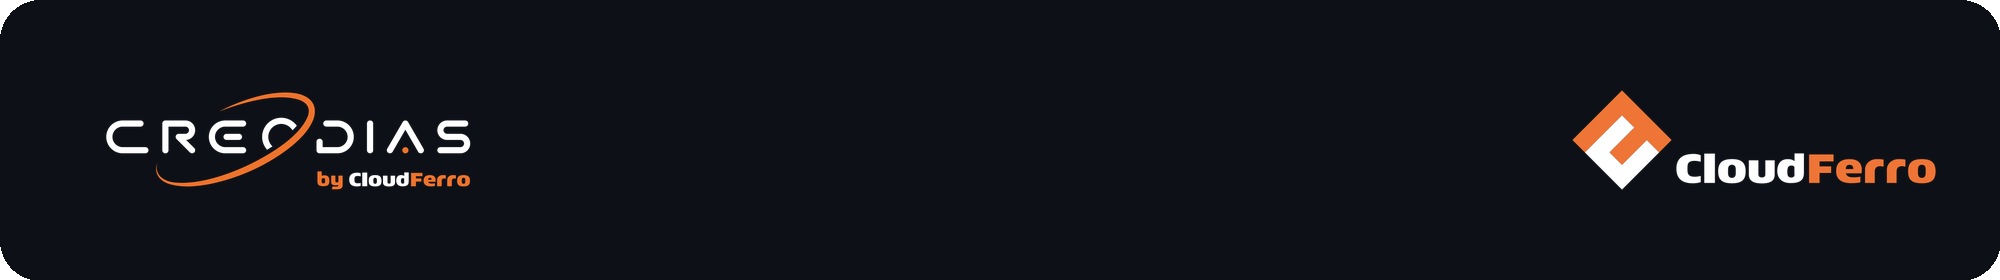


# Measuring forests from space: canopy height from Sentinel-2

In the first notebook we **named** what was on the ground: forest, river, highway. Here we **measure** it. For every 10 m pixel we predict how tall the trees are, in metres, using nothing but a year of Sentinel-2 images.

Why it matters: tree height is one of the strongest predictors of how much wood, and therefore carbon, a forest holds. Measuring it in the field is slow; lasers on aircraft and satellites are precise but patchy. A model that estimates height from free, global, five-day-revisit imagery fills those gaps.

This is a **regression** problem: the answer is a number, not a class. We compare two models:

| Model | Sees | Output |
|---|---|---|
| **Random Forest** | one pixel at a time, as a list of hand-made features | one height per pixel |
| **U-Net** | a whole image block at once | a full height map in one go |

New ideas along the way:

- **time as a feature**: a year of monthly images says more than one snapshot,
- **why vegetation indices saturate** over dense forest,
- **spatial leakage**: the easiest way to fool yourself in Earth observation, and how to avoid it,
- **reading regression results**: error maps, scatter plots, error by height.

One level up from notebook 1, every step explained. About 5 minutes with a GPU once the data is read; the U-Net is slow to train on CPU only.

## The data: OLMOEarth

**OLMOEarth** (Allen Institute for AI) was built to pre-train large Earth observation models. It cuts the world into **tiles of 256 x 256 pixels at 10 m**, 2.56 km on a side, and for each tile stacks many aligned layers: Sentinel-1 radar, Sentinel-2, Landsat, elevation, climate, land cover, OpenStreetMap, and a **canopy height map**.

We use two of them:

| Layer | Folder in `/eodata/geoAI-training/OLMOEarth/` | Content |
|---|---|---|
| Sentinel-2 L2A, monthly | `OLMO_sentinel2_l2a` | 12 consecutive 30-day composites; the 10 m bands (B02, B03, B04, B08) in one file, the 20 m red edge and short-wave infrared bands in another |
| Canopy height | `OLMO_wri_canopy_height_map` | tree height in metres, from the WRI / Meta global map (Tolan et al., 2024) |

**A word of caution about the "truth".** The canopy height map is not a measurement. It is itself the output of a model (Meta and WRI, Tolan et al., 2024) that reads sub-metre satellite photos and was trained on airborne laser scans; OLMOEarth resampled it to 10 m. So we are teaching a small model to imitate a big one from much cheaper input. That is a perfectly good learning exercise, but the reference has known weaknesses:

- **It underestimates the tallest trees.** Independent checks against laser scans found heights several metres too low in tall forest, and the producers note that trees above 25 m were not validated. In our region the map rarely goes above 25 m, while mature Carpathian beech and spruce are often 30 to 40 m tall.
- **It is not one moment in time.** The photos behind it come from different years, and our Sentinel-2 years run from 2015 to 2023. A stand felled or grown in between is an error no model can avoid.

Research maps of canopy height are usually trained on direct laser measurements instead, from NASA's GEDI instrument on the International Space Station or from aircraft. More on that at the end.

All layers of a tile share the same grid, so pixel `[i, j]` in the Sentinel-2 file and in the height file is the same 10 x 10 m patch of ground. No reprojection needed.

## Before you start

This notebook runs on a CREODIAS virtual machine, where the satellite archive is mounted at `/eodata`. You need Python with numpy, pandas, matplotlib, scikit-learn, rasterio, pyproj, folium, tqdm and PyTorch.

With a GPU it takes about five minutes. Without one it switches to a smaller U-Net by itself and takes about a quarter of an hour on a 4-core VM. It needs about 6 GB of memory.

As in notebook 1, the plumbing (finding the hardware, copying files, plot style) sits in one collapsed helper cell, so the rest can stay about forests and models.

## Setup

In [ ]:
# OPTIONAL: only if the imports below fail. Uncomment, run once, then restart the kernel.
# PyTorch must match the VM's CUDA version (`nvidia-smi`, top right). For CUDA 12.8:
#   pip install torch --index-url https://download.pytorch.org/whl/cu128
# import subprocess, sys
# subprocess.run([sys.executable, "-m", "pip", "install", "-q", "numpy", "pandas", "matplotlib", "scikit-learn", "rasterio", "pyproj", "folium", "tqdm", "ipywidgets"], check=True)

In [ ]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import rasterio
from pyproj import Transformer

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings("ignore")

### Helper functions

The next cell defines a few helpers: checking for a GPU, copying files from `/eodata` to local disk, and plot style. Run it; you do not need to read it to follow the tutorial (click it to expand if you are curious).

In [ ]:
# Helper functions. Run this cell; reading it is optional.
import os
import shutil
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

from tqdm.auto import tqdm

plt.rcParams.update({"figure.facecolor": "white", "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})


def choose_settings(speed, full, light):
    """Use `full` settings on a GPU and `light` ones on CPU, unless speed forces one."""
    gpu = torch.cuda.is_available()
    mode = speed if speed in ("full", "light") else ("full" if gpu else "light")
    print("Running on:", f"GPU ({torch.cuda.get_device_name(0)})" if gpu else "CPU (no GPU found)")
    print("Settings:  ", mode + ("  (slow without a GPU!)" if mode == "full" and not gpu else ""))
    if not gpu and shutil.which("nvidia-smi"):
        print("Note: this VM has an NVIDIA GPU, but this PyTorch build cannot use it. Install the "
              "PyTorch build that matches the CUDA version shown by `nvidia-smi`.")
    return ("cuda" if gpu else "cpu"), dict(full if mode == "full" else light)


def notebook_folder():
    """Folder of this notebook file (VS Code and JupyterLab both tell the kernel where it is)."""
    for p in (globals().get("__vsc_ipynb_file__"), os.environ.get("JPY_SESSION_NAME")):
        if p and p.endswith(".ipynb") and Path(p).exists():
            return Path(p).resolve().parent
    return Path.cwd()


DATA_DIR = notebook_folder() / "geoai_data"     # local working copy of the data, next to this notebook


def copy_files(pairs, desc="Copying"):
    """Copy (source, destination) file pairs in parallel and return one True/False per pair.

    Files already on local disk are skipped, so running this again costs nothing.
    A file that fails is retried once; one that still fails is reported as False.
    """
    def present(p):
        return p.exists() and p.stat().st_size > 0

    def copy_one(pair):
        src, dst = pair
        dst.parent.mkdir(parents=True, exist_ok=True)
        tmp = dst.with_name(dst.name + ".part")
        for _ in range(2):
            try:
                shutil.copyfile(src, tmp)
                tmp.rename(dst)
                return
            except OSError:
                time.sleep(1)

    todo = [p for p in pairs if not present(p[1])]
    if todo:
        with ThreadPoolExecutor(16) as pool:   # the storage, not the VM, limits the speed
            list(tqdm(pool.map(copy_one, todo), total=len(todo), desc=desc))
    return [present(dst) for _, dst in pairs]


def storage_error(path):
    return RuntimeError(
        f"Could not copy anything from {path}. Is /eodata mounted? Try `ls {path}` in a terminal. "
        "The storage sometimes refuses requests for a few minutes: wait and run the cell again. "
        "Files already copied are kept.")


def clean_axes(*axes):
    """Image panels: no ticks, no frame."""
    for ax in np.ravel(axes):
        ax.set_xticks([])
        ax.set_yticks([])
        for s in ax.spines.values():
            s.set_visible(False)


def label_line_ends(ax, x, ys, labels):
    """Labels at the right end of lines, nudged apart so they never overlap."""
    lo, hi = ax.get_ylim()
    order = np.argsort(ys)
    pos = np.array(ys, dtype=float)[order]
    for k in range(1, len(pos)):
        pos[k] = max(pos[k], pos[k - 1] + (hi - lo) * 0.045)
    for k, i in enumerate(order):
        ax.annotate(labels[i], (x, ys[i]), xytext=(x, pos[k]), va="center", fontsize=9,
                    color="#333333", annotation_clip=False)

### GPU or CPU?

With a GPU the notebook uses the full settings. Without one it picks lighter ones by itself: a slimmer U-Net trained on smaller image crops, and fewer pixels for the Random Forest. You can force either by changing `speed` to `"full"` or `"light"`.

In [ ]:
SEED = 42   # fixes every random choice, so a rerun gives the same numbers

DEVICE, SETTINGS = choose_settings(
    speed="auto",
    full=dict(unet_width=32, crop=128, rf_pixels=200_000),
    light=dict(unet_width=16, crop=64, rf_pixels=100_000),
)

## Choosing tiles

OLMOEarth cuts the world into squares of 2.56 km inside each UTM zone, and names each tile by its zone (EPSG code), grid column and grid row. Every layer folder on `/eodata` holds an index of its tiles. We copy the index of the canopy height layer (17 MB), keep the tiles inside our region and pick 160 at random.

Our region is the **Carpathians and their foothills** in Slovakia, southern Poland, Hungary, Ukraine and Romania: mountains covered in beech and spruce, valleys of farmland and villages, a good mix of bare fields to mature forest. Change `REGION` to work anywhere else.

In [ ]:
import pandas as pd

INDEX = "OLMO_wri_canopy_height_map/OLMO_wri_canopy_height_map.csv"
source, local = Path("/eodata/geoAI-training/OLMOEarth") / INDEX, DATA_DIR / "OLMOEarth" / INDEX
if not copy_files([(source, local)], "Copying the tile index")[0]:
    raise storage_error(source)
index = pd.read_csv(local)
print(f"OLMOEarth tiles with a canopy height map, worldwide: {len(index):,}")
print(index[["crs", "col", "row", "tile_time"]].head(3).to_string(index=False))

In [ ]:
TILE_SIZE_M = 2560   # 256 px x 10 m


def tile_center_lonlat(epsg, col, row):
    # Centre of a tile in longitude / latitude. Works on single numbers or whole arrays.
    x = (np.asarray(col) + 0.5) * TILE_SIZE_M
    y = -(np.asarray(row) + 0.5) * TILE_SIZE_M
    return Transformer.from_crs(f"EPSG:{epsg}", "EPSG:4326", always_xy=True).transform(x, y)


# Longitude and latitude of every tile, one UTM zone at a time.
index["epsg"] = index["crs"].str.removeprefix("EPSG:").astype(int)
for epsg, rows in index.groupby("epsg").groups.items():
    lon, lat = tile_center_lonlat(epsg, index.loc[rows, "col"], index.loc[rows, "row"])
    index.loc[rows, "lon"], index.loc[rows, "lat"] = lon, lat

REGION = dict(lon=(17, 25), lat=(47, 51))     # degrees east, degrees north
in_region = index[index["lon"].between(*REGION["lon"]) & index["lat"].between(*REGION["lat"])]
picked = in_region.sample(160, random_state=SEED)

candidates = [(e, c, r) for e, c, r in zip(picked["epsg"], picked["col"], picked["row"])]
# Each tile's Sentinel-2 year is 12 periods of 30 days, starting 187 days before its reference time.
START = {t: np.datetime64(tt[:10]) - np.timedelta64(187, "D") for t, tt in zip(candidates, picked["tile_time"])}
print(f"{len(in_region)} tiles in the region; picked {len(candidates)} at random, for example:")
for (e, c, r), lo, la in zip(candidates[:3], picked["lon"], picked["lat"]):
    print(f"  EPSG:{e}  column {c}  row {r}   centre {la:.3f} N {lo:.3f} E   year starts {START[(e, c, r)]}")

In [ ]:
OLMO = Path("/eodata/geoAI-training/OLMOEarth")
LOCAL = DATA_DIR / "OLMOEarth"


def olmo_name(layer, tile, res=10):
    # e.g. OLMO_sentinel2_l2a/OLMO_sentinel2_l2a_EPSG_32634_322_-2160_10.tif
    epsg, col, row = tile
    return f"OLMO_{layer}/OLMO_{layer}_EPSG_{epsg}_{col}_{row}_{res}.tif"


def copy_layer(layer, tiles, res=10):
    # Copy one layer for many tiles to local disk; returns {tile: local file} for those that made it.
    names = [olmo_name(layer, t, res) for t in tiles]
    ok = copy_files([(OLMO / n, LOCAL / n) for n in names], f"Copying {layer} ({res} m)")
    if not any(ok):
        raise storage_error(OLMO / f"OLMO_{layer}")
    return {t: LOCAL / n for t, n, good in zip(tiles, names, ok) if good}

### Reading the canopy height maps

We first read only the height layer of every candidate, which is small, and keep tiles where trees cover a reasonable share of the ground. A tile that is all farmland or all forest teaches the model little about the transition between them.

Heights above 60 m or marked as *no data* are treated as missing.

In [ ]:
height_files = copy_layer("wri_canopy_height_map", candidates)


def load_height(path):
    with rasterio.open(path) as ds:
        h = ds.read(1).astype(np.float32)
    h[(h > 60) | (h < 0)] = np.nan       # not a plausible tree height: treat as missing
    return h


heights = {t: load_height(f) for t, f in height_files.items()}
tree_share = {t: float(np.nanmean(h >= 5)) for t, h in heights.items()}

# Keep tiles where at least 15% of the ground has trees of 5 m or more.
eligible = [t for t, share in tree_share.items() if share >= 0.15 and np.isnan(heights[t]).mean() < 0.05]
rng = np.random.default_rng(SEED)
eligible = [eligible[i] for i in rng.permutation(len(eligible))]   # fixed random order
print(f"{len(eligible)} of {len(heights)} tiles have enough trees")

### Reading Sentinel-2

Sentinel-2 comes in two files per tile. The 10 m file holds blue, green, red and near infrared (B02, B03, B04, B08); the 20 m file holds the three **red edge** bands, the narrow near infrared and two **short-wave infrared** bands (B05, B06, B07, B8A, B11, B12). Each holds twelve consecutive 30-day periods, and each period is a composite: the clearest view the archive had in those 30 days.

Why bother with the 20 m bands? The red edge is where vegetation reflectance climbs steeply, and its exact position and steepness change with how much leaf and wood there is; short-wave infrared responds to water in leaves and to canopy shadow. Studies of forest height and biomass consistently find that these bands help exactly where NDVI gives up, in dense forest. We stretch the 20 m pixels to 10 m, each one becoming a 2 x 2 block, so all ten bands share one grid.

Two things need care before the data is usable:

1. **The year does not start in January.** Every tile's twelve periods begin on its own date, and in its own year, anywhere from 2015 to 2023. Layer 0 is January for one tile and November for the next. We use the start date to give each period its calendar month and put them in order, January to December.
2. **Composites are not always clear.** In a cloudy month the best view can still be cloud, and in the Carpathian winter it is often snow. There is no cloud mask in the files, so we make a simple one: clouds and snow are very bright in blue light, while vegetation, soil and water stay below about 0.1. Pixels with blue reflectance above 0.15 (`CLOUD_BLUE`) are marked missing and filled with the pixel's median over the other months.

Values are divided by 10,000 to get reflectance, as in notebook 1. Our tiles span 2015 to 2023, across the January 2022 change that added a +1000 offset to Sentinel-2 values; OLMOEarth has already removed that offset, so the same division is right for every year (the darkest pixels stay near 0 before and after 2022).

In [ ]:
S2_BANDS = ["B02", "B03", "B04", "B08",                   # 10 m: blue, green, red, near infrared
            "B05", "B06", "B07", "B8A", "B11", "B12"]     # 20 m: red edge 1-3, narrow NIR, SWIR 1-2
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]


def calendar_order(stack, start):
    # stack: (12 periods, bands, y, x) -> (12 calendar months, bands, y, x).
    # Each 30-day period goes to the month its midpoint falls in; two periods in one month
    # are averaged, a month no period falls in stays missing and is filled later.
    out = np.full_like(stack, np.nan)
    count = np.zeros(12)
    for k in range(stack.shape[0]):
        mid = start + np.timedelta64(30 * k + 15, "D")
        m = int(str(mid)[5:7]) - 1
        out[m] = stack[k] if count[m] == 0 else np.nanmean([out[m], stack[k]], axis=0)
        count[m] += 1
    return out


CLOUD_BLUE = 0.15   # blue reflectance above this = cloud or snow


def load_s2(path10, path20, start):
    with rasterio.open(path10) as ds:
        a10 = ds.read().reshape(12, 4, 256, 256)
    with rasterio.open(path20) as ds:
        a20 = ds.read().reshape(12, 6, 128, 128)
    a20 = a20.repeat(2, axis=2).repeat(2, axis=3)                 # 20 m -> 10 m: each pixel becomes 2 x 2
    s2 = np.concatenate([a10, a20], axis=1).astype(np.float32) / 10000.0
    bad = (s2 <= 0).any(axis=1) | (s2[:, 0] > CLOUD_BLUE)      # no data, cloud or snow
    s2[np.broadcast_to(bad[:, None], s2.shape)] = np.nan
    s2 = calendar_order(s2, start)
    fill = np.nanmedian(s2, axis=0, keepdims=True)
    s2 = np.nan_to_num(np.where(np.isnan(s2), fill, s2), nan=0.0)
    return s2.astype(np.float16), bad.mean()       # half precision: plenty for reflectance, half the memory


def full_year(path, bands_per_period):
    # A tile is usable if its file holds all 12 periods.
    with rasterio.open(path) as ds:
        return ds.count == 12 * bands_per_period


# 80 tiles of 2.56 x 2.56 km, both resolutions: about 0.7 GB to copy. A few spares, in case
# some tiles lack part of their year.
files10 = copy_layer("sentinel2_l2a", eligible[:90], res=10)
files20 = copy_layer("sentinel2_l2a", list(files10), res=20)
tiles = [t for t in files10 if t in files20 and full_year(files10[t], 4) and full_year(files20[t], 6)][:80]

# One array for all tiles, filled tile by tile so the data is never held twice.
S2 = np.zeros((len(tiles), 12, len(S2_BANDS), 256, 256), dtype=np.float16)   # tiles, months, bands, y, x
masked = []
for k, t in enumerate(tiles):
    S2[k], share = load_s2(files10[t], files20[t], START[t])
    masked.append(share)
H = np.stack([heights[t] for t in tiles])            # (tiles, 256, 256)
print(f"Loaded {len(tiles)} tiles")
print(f"Cloud, snow or no data: {np.mean(masked):.0%} of all monthly pixels, filled")
print(f"Sentinel-2 cube: {S2.shape}  ->  {S2.nbytes / 1e9:.1f} GB in memory")
print(f"Height maps:     {H.shape}")

### Where are we?

An interactive map (drag to move, scroll to zoom): each square is one tile, its real 2.56 km footprint, coloured by the share of the tile covered by trees of 5 m or more. Hover over a tile to see its numbers. The map tiles come from OpenStreetMap, so this needs an internet connection in your browser.

In [ ]:
import folium
from matplotlib.colors import to_hex

greens = plt.get_cmap("Greens")
lonlat = np.array([tile_center_lonlat(*t) for t in tiles])
fmap = folium.Map(location=[lonlat[:, 1].mean(), lonlat[:, 0].mean()], zoom_start=7, tiles="OpenStreetMap")
for (epsg, col, row), (lon, lat) in zip(tiles, lonlat):
    share = tree_share[(epsg, col, row)]
    to_ll = Transformer.from_crs(f"EPSG:{epsg}", "EPSG:4326", always_xy=True)
    x0, y0 = col * TILE_SIZE_M, -row * TILE_SIZE_M                       # top-left corner in UTM metres
    corners = [to_ll.transform(x, y) for x, y in
               [(x0, y0), (x0 + TILE_SIZE_M, y0), (x0 + TILE_SIZE_M, y0 - TILE_SIZE_M), (x0, y0 - TILE_SIZE_M)]]
    folium.Polygon([(la, lo) for lo, la in corners], color="#333333", weight=1,
                   fill=True, fill_color=to_hex(greens(0.2 + 0.8 * share)), fill_opacity=0.8,
                   tooltip=f"{lat:.3f} N {lon:.3f} E: trees on {share:.0%} of the tile").add_to(fmap)
    folium.CircleMarker((lat, lon), radius=4, color="#333333", weight=1, fill=True,
                        fill_color=to_hex(greens(0.2 + 0.8 * share)), fill_opacity=1,
                        tooltip=f"trees on {share:.0%} of the tile").add_to(fmap)
fmap

## A first look

For a few tiles: a summer true colour image, a false colour image with near infrared as red, and the canopy height map. Notice how the false colour already separates forest (dark, deep red) from meadows and crops (bright red, or grey when bare), but says little about *how tall* the trees are.

You may also spot the limits of our simple cloud mask: the fringe of a cloud, a dark cloud shadow, or a black blob where a pixel was hidden in every single month. A brightness threshold catches thick clouds but not their shadows. Sentinel-2 L2A products normally come with a **scene classification layer (SCL)** that flags clouds and shadows, but this dataset ships only the spectral bands. Learning a proper cloud and shadow mask is exactly what the **CloudSEN12** dataset in this collection is for.

In [ ]:
def rgb(s2_tile, month=6, bands=(2, 1, 0), gain=3.5):
    img = np.stack([s2_tile[month, b] for b in bands], axis=-1).astype(np.float32) * gain
    return np.clip(img, 0, 1) ** 0.9


H_MAX = 30
show = np.argsort([-np.nanstd(h) for h in H])[:4]     # the four most varied tiles
fig, axes = plt.subplots(3, len(show), figsize=(len(show) * 3.2, 10.4), layout="constrained")
for c, i in enumerate(show):
    axes[0, c].imshow(rgb(S2[i]))
    axes[1, c].imshow(rgb(S2[i], bands=(3, 2, 1), gain=2.5))
    im = axes[2, c].imshow(H[i], cmap="Greens", vmin=0, vmax=H_MAX)
    axes[0, c].set_title(f"{lonlat[i, 1]:.2f}°N {lonlat[i, 0]:.2f}°E", fontsize=9)
clean_axes(axes)
for r, label in enumerate(["True colour (July)", "False colour (July)", "Canopy height"]):
    axes[r, 0].set_ylabel(label)
fig.colorbar(im, ax=axes[2, :], location="bottom", shrink=0.5, label="Tree height (m)")
plt.show()

## The target: canopy height

The number we predict for every pixel is **tree height in metres** from the canopy height map, shown in the bottom row above. It plays the role of *ground truth*, but it is itself the output of another model (see the caution at the top), so it is better called **pseudo ground truth**: the best reference we have, not a measurement.

How the heights are distributed over all our tiles:

In [ ]:
h = H[~np.isnan(H)]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(h, bins=np.arange(-0.5, 36), color="#2a78d6", edgecolor="white", weights=np.full(h.size, 100 / h.size))
ax.set_xlabel("Canopy height (m)")
ax.set_ylabel("Share of pixels (%)")
ax.set_title("Reference heights over all tiles", loc="left")
plt.tight_layout()
plt.show()
print(f"No trees (under 1 m): {np.mean(h < 1):.0%} of pixels.   Trees of 5 m or more: {np.mean(h >= 5):.0%}.")
print(f"Median height where there are trees: {np.median(h[h >= 5]):.0f} m.   Tallest: {h.max():.0f} m "
      f"(only {np.mean(h >= 25):.1%} of pixels reach 25 m).")

## Time is a feature

A single image is one moment. Twelve monthly images show how each pixel **changes through the year**, and different vegetation has different rhythms:

- **conifers** stay green all year,
- **broadleaf forest** greens up in May and fades in October,
- **crops** shoot up and are harvested, sometimes twice a year,
- **grassland** follows the rain and the mower.

Below: the median NDVI through the year for pixels grouped by tree height. In summer the three forest groups sit on top of each other. In **winter** they separate a little more. Part of the reason is likely that many tall stands here are spruce and fir, which keep their needles, while low vegetation browns or disappears under snow. So the *winter* months carry information about height that a summer image alone does not. And in summer, hold that thought, NDVI can no longer tell a 10 m forest from a 20 m one.

In [ ]:
def ndvi(s2):
    # s2[..., month, band, y, x] -> NDVI per month
    nir, red = s2[..., 3, :, :].astype(np.float32), s2[..., 2, :, :].astype(np.float32)
    return (nir - red) / (nir + red + 1e-6)


NDVI = ndvi(S2)                                       # (tiles, 12, 256, 256)
bins = [(0, 1, "no trees, < 1 m"), (1, 5, "shrubs, 1-5 m"), (5, 12, "young forest, 5-12 m"),
        (12, 18, "forest, 12-18 m"), (18, 60, "tall forest, > 18 m")]
ramp = ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]

fig, ax = plt.subplots(figsize=(9, 4.6))
nd = NDVI.transpose(1, 0, 2, 3).reshape(12, -1)
hh = H.reshape(-1)
ends = []
for (lo, hi, label), col in zip(bins, ramp):
    m = (hh >= lo) & (hh < hi)
    curve = np.median(nd[:, m], axis=1)
    ax.plot(MONTHS, curve, color=col, linewidth=2.2, marker="o", markersize=5)
    ends.append(curve[-1])
ax.set_ylabel("Median NDVI")
ax.set_xlim(-0.3, 14.5)
label_line_ends(ax, 11.3, ends, [b[2] for b in bins])
ax.set_title("A year in the life of a pixel, by tree height", loc="left")
plt.tight_layout()
plt.show()

## Why NDVI alone is not enough: saturation

Plot summer NDVI against tree height for every pixel. NDVI climbs fast from bare ground to a closed canopy, then **flattens out**: a 10 m and a 30 m forest both cover the ground completely, so from above, in red and near infrared, they look almost the same. This is called **saturation**, and it is a classic limit of optical remote sensing.

Our models will need more subtle clues: shadows and texture of the canopy, seasonal behaviour, the context of where a pixel sits.

In [ ]:
rng = np.random.default_rng(SEED)
pick = rng.choice(hh.size, 300_000, replace=False)
summer_ndvi = NDVI[:, 5:8].mean(axis=1).reshape(-1)[pick]
fig, ax = plt.subplots(figsize=(8, 5))
# Reference heights are whole metres, so one column per metre.
*_, hb = ax.hist2d(hh[pick], summer_ndvi, bins=[np.arange(-0.5, 34), np.linspace(-0.2, 1.0, 61)],
                   cmap="Blues", norm=LogNorm(), cmin=5)
ax.set_xlabel("Canopy height (m)")
ax.set_ylabel("Summer NDVI (Jun-Aug)")
fig.colorbar(hb, ax=ax, label="Pixels (log scale)")
ax.set_title("NDVI rises with height, then saturates", loc="left")
plt.tight_layout()
plt.show()

## Spatial leakage: the easiest way to fool yourself

Before training anything, decide how to test. The tempting way is to pool all pixels and pick a random 25% for testing. **Do not do this with maps.**

Neighbouring pixels are almost copies of each other: same forest stand, same field. If pixel A is in the training set and its neighbour B is in the test set, the model has effectively seen the answer. The score looks great and means little, because the model will be used on places it has never seen.

The honest approach is to hold back **entire tiles**. Below we do both and compare, so you can see the size of the illusion.

Even whole tiles are not a perfect shield. Similarity between places fades over tens of kilometres, so a test tile next to a training tile is still a little too easy. The cell prints how far each test tile is from its nearest training tile. For a stricter test, researchers hold out whole regions at once (spatial block cross-validation).

In [ ]:
rng = np.random.default_rng(SEED)
order = rng.permutation(len(tiles))
test_t, train_t = order[:20], order[20:]   # 20 whole tiles held back for testing
print(f"Training tiles: {len(train_t)}   Test tiles: {len(test_t)}")


def km_between(a, b):
    # Great-circle distance in km between (lon, lat) points.
    lon1, lat1, lon2, lat2 = map(np.radians, (a[..., 0], a[..., 1], b[..., 0], b[..., 1]))
    h = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(h))


gap = np.array([km_between(lonlat[t], lonlat[train_t]).min() for t in test_t])
print(f"Distance from a test tile to the nearest training tile: median {np.median(gap):.0f} km, "
      f"closest {gap.min():.0f} km, {np.sum(gap < 10)} tiles closer than 10 km")

## Model 1: Random Forest, pixel by pixel

The Random Forest is the same algorithm we built step by step in notebook 1 (see there if trees, bootstrap samples and voting are new to you). Only one thing changes for regression: each tree's leaf holds the **average height** of its training pixels instead of a class, and the forest **averages** its trees instead of counting votes.

Features per pixel, 40 in total:

- **monthly NDVI**, 12 values: the seasonal curve above,
- **median reflectance** of all ten bands over the year, 10 values,
- **summer reflectance** of all ten bands, June to August, 10 values,
- **NDVI statistics**: minimum, maximum and amplitude over the year, 3 values,
- **summer red edge index** (NDRE), (B8A - B05) / (B8A + B05): like NDVI but using the red edge, which keeps responding in dense canopies where NDVI has saturated, 1 value,
- **texture**: the standard deviation of summer NIR and NDVI in the surrounding 5 x 5 pixels, plus their local mean, 4 values. Tall forest canopies are rough, with crowns and shadows; young forest and fields are smooth. This gives a pixel-wise model a little spatial context.

In [ ]:
def local_stats(img, k=5):
    # Mean and standard deviation in a k x k window around every pixel.
    t = torch.from_numpy(img)[None, None]
    mean = F.avg_pool2d(F.pad(t, (k // 2,) * 4, mode="reflect"), k, stride=1)
    sq = F.avg_pool2d(F.pad(t * t, (k // 2,) * 4, mode="reflect"), k, stride=1)
    return mean[0, 0].numpy(), np.sqrt(np.clip(sq - mean * mean, 0, None))[0, 0].numpy()


FEATURE_NAMES = ([f"NDVI {m}" for m in MONTHS] + [f"median {b}" for b in S2_BANDS]
                 + [f"summer {b}" for b in S2_BANDS] + ["NDVI min", "NDVI max", "NDVI amplitude"]
                 + ["NDRE summer"]
                 + ["NIR local mean", "NIR local std", "NDVI local mean", "NDVI local std"])


def tile_features(i):
    s2, nd = S2[i].astype(np.float32), NDVI[i]
    summer = s2[5:8].mean(axis=0)
    summer_nd = nd[5:8].mean(axis=0)
    b = {name: k for k, name in enumerate(S2_BANDS)}
    ndre = (summer[b["B8A"]] - summer[b["B05"]]) / (summer[b["B8A"]] + summer[b["B05"]] + 1e-6)
    nir_m, nir_s = local_stats(summer[3])
    nd_m, nd_s = local_stats(summer_nd)
    feats = np.concatenate([
        nd, np.median(s2, axis=0), summer,
        nd.min(axis=0)[None], nd.max(axis=0)[None], (nd.max(axis=0) - nd.min(axis=0))[None],
        ndre[None],
        nir_m[None], nir_s[None], nd_m[None], nd_s[None],
    ])
    return feats.reshape(len(FEATURE_NAMES), -1).T          # (65536 pixels, 40 features)


FEAT = np.zeros((len(tiles), 256 * 256, len(FEATURE_NAMES)), dtype=np.float32)   # tiles, pixels, features
for i in range(len(tiles)):
    FEAT[i] = tile_features(i)
TARGET = H.reshape(len(tiles), -1)
print(f"Feature cube: {FEAT.shape}")


def sample_pixels(tile_ids, n, rng):
    # Random pixels with a reference height from the given tiles, as (features, heights).
    per_tile = TARGET.shape[1]
    idx = (np.asarray(tile_ids)[:, None] * per_tile + np.arange(per_tile)).ravel()
    idx = idx[~np.isnan(TARGET.reshape(-1)[idx])]
    pick = rng.choice(idx, min(n, idx.size), replace=False)
    return FEAT.reshape(-1, FEAT.shape[-1])[pick], TARGET.reshape(-1)[pick]

### The leakage experiment

Same model, same amount of training data, two ways of testing.

In [ ]:
rng = np.random.default_rng(SEED)
all_t = np.arange(len(tiles))

# Wrong: random pixels from all tiles for both training and testing.
n_pix = SETTINGS["rf_pixels"]   # training pixels for the forest
Xa, ya = sample_pixels(all_t, n_pix + 100_000, rng)
rf_leaky = RandomForestRegressor(n_estimators=100, min_samples_leaf=20, n_jobs=-1, random_state=SEED)
rf_leaky.fit(Xa[:n_pix], ya[:n_pix])
mae_leaky = mean_absolute_error(ya[n_pix:], rf_leaky.predict(Xa[n_pix:]))
del rf_leaky, Xa, ya   # a forest takes a lot of memory; this one has done its job

# Right: train on training tiles, test on tiles the model has never seen.
X_tr, y_tr = sample_pixels(train_t, n_pix, rng)
t0 = time.time()
rf = RandomForestRegressor(n_estimators=100, min_samples_leaf=20, n_jobs=-1, random_state=SEED)
rf.fit(X_tr, y_tr)
rf_fit_s = time.time() - t0

y_true_test = TARGET[test_t].reshape(-1)
rf_pred_test = rf.predict(FEAT[test_t].reshape(-1, FEAT.shape[-1]))
ok = ~np.isnan(y_true_test)
mae_honest = mean_absolute_error(y_true_test[ok], rf_pred_test[ok])

print(f"Random pixel split (leaky):  MAE {mae_leaky:.2f} m")
print(f"Held-out tiles (honest):     MAE {mae_honest:.2f} m")
print(f"The leaky test looks {100 * (1 - mae_leaky / mae_honest):.0f}% better than reality.")

The gap is the illusion. From here on, every number comes from the held-out test tiles.

### What does the forest rely on?

Near the top you will find summer reflectance in the **visible red (B04)**, **green (B03)** and the first **red edge** band (B05): how dark the canopy is where chlorophyll still absorbs light. A tall, closed canopy is rough, and big crowns cast deep shadows into the gaps, so from above it looks *darker* than a young, even stand. The local texture features capture the same roughness directly. The exact ranking changes with the tiles drawn, and importance is shared out among features that carry similar information, so read it as a rough guide.

In [ ]:
imp = rf.feature_importances_
top = np.argsort(imp)[::-1][:12][::-1]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(range(len(top)), imp[top], color="#2a78d6", height=0.7)
ax.set_yticks(range(len(top)), [FEATURE_NAMES[i] for i in top])
for k, i in enumerate(top):
    ax.text(imp[i], k, f" {imp[i]:.3f}", va="center", fontsize=8, color="#52514e")
ax.set_xlabel("Importance")
ax.set_title("Top 12 features for canopy height", loc="left")
plt.tight_layout()
plt.show()

### Do the invisible bands help?

Earlier we claimed the red edge and short-wave infrared bands help where NDVI saturates. Let us check rather than trust it: train the same forest twice on the same pixels, once with only the features built from the four 10 m bands, once with everything, and compare the error on the test tiles, overall and on forest taller than 15 m.

In [ ]:
only_10m = [k for k, name in enumerate(FEATURE_NAMES)
            if not any(band in name for band in S2_BANDS[4:]) and "NDRE" not in name]
rf_10m = RandomForestRegressor(n_estimators=100, min_samples_leaf=20, n_jobs=-1, random_state=SEED)
rf_10m.fit(X_tr[:, only_10m], y_tr)
pred_10m = rf_10m.predict(FEAT[test_t].reshape(-1, FEAT.shape[-1])[:, only_10m])
del rf_10m

tall = ok & (y_true_test > 15)
print(f"{'Features':<36}{'MAE all':>9}{'MAE > 15 m':>12}")
for label, pred in [(f"10 m bands only ({len(only_10m)} features)", pred_10m),
                    (f"plus red edge and SWIR ({len(FEATURE_NAMES)})", rf_pred_test)]:
    print(f"{label:<36}{mean_absolute_error(y_true_test[ok], pred[ok]):>8.2f} m"
          f"{mean_absolute_error(y_true_test[tall], pred[tall]):>10.2f} m")

The extra bands help, modestly overall and a little more on tall forest. That matches the research: red edge and short-wave infrared push back saturation but do not remove it, and errors on tall trees stay large for any pixel-by-pixel model. Keep an eye on whether the U-Net, which also sees the neighbourhood, does better there.

## Model 2: a small U-Net

The Random Forest sees one pixel plus a 5 x 5 neighbourhood that we described for it. A **U-Net** looks at a whole block of the image and learns for itself which patterns around a pixel matter. It is built from the same parts as the CNN in notebook 1 (convolutions, ReLU, pooling, gradient steps on a loss), arranged so that the output is a full map instead of one class.

Its shape gives it the name:

- the **encoder** (left side of the U) repeatedly convolves and shrinks the image, so deeper layers see wider context: a crown, a stand, a valley slope;
- the **decoder** (right side) grows it back to full size to produce one value per pixel;
- **skip connections** carry fine detail straight across the U, so edges in the output stay sharp.

U-Nets were invented for medical images in 2015 and are now the default for anything that turns an image into a map.

The input is **four seasonal averages** (winter, spring, summer, autumn) of all ten bands: 40 layers, normalised per layer. Twelve months of ten bands would be 120 layers, three times the memory and compute for little extra information. Training uses random crops (128 x 128 pixels, or 64 x 64 in the light settings) from the training tiles with random flips and rotations, and an **L1 loss**: the average absolute error in metres, ignoring pixels with no reference height.

In [ ]:
torch.manual_seed(SEED)

SEASONS = {"winter": [11, 0, 1], "spring": [2, 3, 4], "summer": [5, 6, 7], "autumn": [8, 9, 10]}
X_cube = np.zeros((len(tiles), 4 * len(S2_BANDS), 256, 256), dtype=np.float32)   # 4 seasons x 10 bands
for k in range(len(tiles)):
    X_cube[k] = np.concatenate([S2[k, months].astype(np.float32).mean(axis=0) for months in SEASONS.values()])

# Normalise every layer with the mean and spread of the training tiles, in place to save memory.
m1 = np.mean([X_cube[k].mean(axis=(1, 2)) for k in train_t], axis=0)
m2 = np.mean([(X_cube[k] ** 2).mean(axis=(1, 2)) for k in train_t], axis=0)
X_cube -= m1[None, :, None, None]
X_cube /= np.sqrt(m2 - m1 ** 2)[None, :, None, None] + 1e-6
Xt = torch.from_numpy(X_cube)      # shares memory with X_cube, no copy
Ht = torch.from_numpy(H)


def conv_block(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
    )


class UNet(nn.Module):
    def __init__(self, c_in=Xt.shape[1], w=SETTINGS["unet_width"]):
        widths = (w, 2 * w, 4 * w, 8 * w)   # filters double at every level of the U
        super().__init__()
        self.down = nn.ModuleList()
        c = c_in
        for w in widths:
            self.down.append(conv_block(c, w))
            c = w
        self.up = nn.ModuleList()
        self.up_conv = nn.ModuleList()
        for w in reversed(widths[:-1]):
            self.up.append(nn.ConvTranspose2d(c, w, 2, stride=2))
            self.up_conv.append(conv_block(2 * w, w))
            c = w
        self.out = nn.Conv2d(c, 1, 1)

    def forward(self, x):
        skips = []
        for i, block in enumerate(self.down):
            x = block(x)
            if i < len(self.down) - 1:
                skips.append(x)
                x = F.max_pool2d(x, 2)
        for up, conv, skip in zip(self.up, self.up_conv, reversed(skips)):
            x = conv(torch.cat([up(x), skip], dim=1))
        return F.relu(self.out(x))[:, 0]              # heights are never negative


def random_crops(tile_ids, n, size=SETTINGS["crop"]):
    ti = np.random.choice(tile_ids, n)
    ys, xs = np.random.randint(0, 256 - size + 1, (2, n))
    xb = torch.stack([Xt[t, :, y:y + size, x:x + size] for t, y, x in zip(ti, ys, xs)])
    hb = torch.stack([Ht[t, y:y + size, x:x + size] for t, y, x in zip(ti, ys, xs)])
    k = np.random.randint(4)
    xb, hb = torch.rot90(xb, k, (-2, -1)), torch.rot90(hb, k, (-2, -1))
    if np.random.rand() < 0.5:
        xb, hb = xb.flip(-1), hb.flip(-1)
    return xb, hb


def masked_l1(pred, target):
    ok = ~torch.isnan(target)
    return (pred[ok] - target[ok]).abs().mean()


def predict_tiles(model, tile_ids):
    model.eval()
    with torch.no_grad():
        return np.stack([model(Xt[t:t + 1].to(DEVICE))[0].cpu().numpy() for t in tile_ids])


np.random.seed(SEED)
unet = UNet().to(DEVICE)
print(f"U-Net parameters: {sum(p.numel() for p in unet.parameters()):,}")
EPOCHS, STEPS, BATCH = 40, 60, 16   # 40 rounds of 60 batches of 16 crops
opt = torch.optim.AdamW(unet.parameters(), lr=1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=1e-3, total_steps=EPOCHS * STEPS)

history = []
t0 = time.time()
for ep in range(EPOCHS):
    unet.train()
    losses = []
    for _ in range(STEPS):
        xb, hb = random_crops(train_t, BATCH)
        loss = masked_l1(unet(xb.to(DEVICE)), hb.to(DEVICE))
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
        losses.append(loss.item())
    test_pred = predict_tiles(unet, test_t)
    ok_t = ~np.isnan(H[test_t])
    history.append((np.mean(losses), np.abs(test_pred - H[test_t])[ok_t].mean()))
    if ep == 0 or (ep + 1) % 5 == 0:
        print(f"epoch {ep + 1:>3}  train L1 {history[-1][0]:.2f} m   test MAE {history[-1][1]:.2f} m")
unet_fit_s = time.time() - t0
unet_pred_test = predict_tiles(unet, test_t)

How to read the learning curve: all three lines are the **mean absolute error in metres** (lower is better). Blue is the U-Net on the training crops it learns from; green is the U-Net on the 20 test tiles, measured after every epoch; the dashed orange line is the final error of the Random Forest on the same test tiles, for comparison.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(range(1, EPOCHS + 1), [h[0] for h in history], color="#2a78d6", linewidth=2)
ax.plot(range(1, EPOCHS + 1), [h[1] for h in history], color="#1baf7a", linewidth=2)
ax.axhline(mae_honest, color="#eb6834", linestyle="--", linewidth=1)
ax.annotate("U-Net, training crops", (EPOCHS, history[-1][0]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9)
ax.annotate("U-Net, test tiles", (EPOCHS, history[-1][1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9)
ax.annotate("Random Forest, test tiles (final result)", (1, mae_honest), xytext=(0, 4), textcoords="offset points", fontsize=8, color="#52514e")
ax.set_xlim(0, EPOCHS * 1.35)
ax.set_xlabel("Epoch")
ax.set_ylabel("Mean absolute error (m)")
ax.set_title("U-Net learning curve", loc="left")
plt.tight_layout()
plt.show()

## Comparing the two

Three standard regression scores, all on the held-out test tiles:

- **MAE**, mean absolute error: on average, how many metres off the prediction is,
- **RMSE**, root mean squared error: like MAE but punishes big misses more,
- **R²**: the share of the variation in height the model explains; 1 is perfect, 0 is no better than always guessing the average.

In [ ]:
MODEL_COLORS = {"Random Forest": "#2a78d6", "U-Net": "#1baf7a"}
truth = H[test_t].reshape(-1)
ok = ~np.isnan(truth)
PRED = {"Random Forest": rf_pred_test, "U-Net": unet_pred_test.reshape(-1)}
FIT_S = {"Random Forest": rf_fit_s, "U-Net": unet_fit_s}

print(f"{'Model':<15}{'MAE (m)':>9}{'RMSE (m)':>10}{'R²':>7}{'Train time':>12}")
for n, p in PRED.items():
    print(f"{n:<15}{mean_absolute_error(truth[ok], p[ok]):>9.2f}"
          f"{np.sqrt(mean_squared_error(truth[ok], p[ok])):>10.2f}"
          f"{r2_score(truth[ok], p[ok]):>7.2f}{FIT_S[n]:>10.0f} s")

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
for ax, (n, p) in zip(axes, PRED.items()):
    *_, hb = ax.hist2d(truth[ok], p[ok], bins=[np.arange(-0.5, 34), np.linspace(0, 33, 67)],
                       cmap="Blues", norm=LogNorm(), cmin=3)
    ax.plot([0, 33], [0, 33], color="#e34948", linewidth=1, linestyle="--", label="perfect prediction")
    # The model's typical answer: median prediction for every metre of reference height.
    metres = np.arange(0, 31)
    in_bin = [ok & (np.round(truth) == m) for m in metres]
    med = [np.median(p[b]) if b.sum() >= 200 else np.nan for b in in_bin]   # skip heights with few pixels
    ax.plot(metres, med, color="#0b0b0b", linewidth=2, label="median prediction")
    ax.legend(loc="upper left", frameon=False, fontsize=9)
    ax.set_title(n, loc="left")
    ax.set_xlabel("Reference height (m)")
    ax.set_aspect("equal")
axes[0].set_ylabel("Predicted height (m)")
fig.suptitle("Predicted vs reference height on the test tiles (darker = more pixels)", x=0.01, ha="left", fontsize=11)
plt.tight_layout()
plt.show()

The red dashed line is where a perfect model would sit; the black line is what each model typically answers. Both models **underestimate tall trees**, and the Random Forest also **overestimates low vegetation**. This *regression to the mean* is typical: when the input is ambiguous, the safest guess is somewhere in the middle. Saturation makes the tall end ambiguous, so tall forests get pulled down.

### Error by height

In [ ]:
edges = np.array([0, 2, 5, 10, 15, 20, 25, 35])
centers = (edges[:-1] + edges[1:]) / 2
fig, ax = plt.subplots(figsize=(9, 4.4))
ends = []
for n, p in PRED.items():
    bias = [np.mean(p[ok & (truth >= lo) & (truth < hi)] - truth[ok & (truth >= lo) & (truth < hi)])
            for lo, hi in zip(edges[:-1], edges[1:])]
    ax.plot(centers, bias, color=MODEL_COLORS[n], linewidth=2, marker="o", markersize=7,
            markeredgecolor="white", markeredgewidth=1.5)
    ends.append(bias[-1])
ax.axhline(0, color="#c3c2b7", linewidth=1)
ax.set_xticks(centers, [f"{lo}-{hi}" for lo, hi in zip(edges[:-1], edges[1:])])
ax.set_xlim(centers[0] - 2, centers[-1] + 9)
label_line_ends(ax, centers[-1] + 1.2, ends, list(PRED))
ax.set_xlabel("Reference height (m)")
ax.set_ylabel("Mean error, predicted minus reference (m)")
ax.set_title("Bias: positive = too tall, negative = too short", loc="left")
plt.tight_layout()
plt.show()

## The maps

The real test is visual. Each row is one test tile the models never saw during training: the image, the reference height, the two predictions, and where the U-Net is wrong (red: too tall, blue: too short).

Notice the texture. The Random Forest works pixel by pixel and looks speckled; the U-Net produces coherent stands with clean edges, because it sees the neighbourhood.

And look for a tile where haze or cloud slipped through our simple mask. Both models then see a paler, flatter image and predict trees that are much too short: the error map turns blue across the whole forest. No model can recover what the input does not show, which is why cloud masking matters so much in practice.

Keep in mind that part of every difference is not the models' fault. The reference map is a finished product from another source: a model that reads sub-metre commercial satellite photos (trained on airborne lidar), made from images of different years than our Sentinel-2 data. Sharp crowns and gaps visible at 1 m cannot be fully recovered from 10 m pixels, and a stand cut or grown between the two dates shows up as an error.

In [ ]:
rf_maps = rf_pred_test.reshape(len(test_t), 256, 256)
rows = np.argsort([-np.nanstd(H[t]) for t in test_t])[:4]

fig, axes = plt.subplots(len(rows), 5, figsize=(16, 3.4 * len(rows) + 0.8), layout="constrained")
for r, k in enumerate(rows):
    t = test_t[k]
    err = unet_pred_test[k] - H[t]
    panels = [
        (rgb(S2[t]), None, None),
        (H[t], "Greens", (0, H_MAX)),
        (rf_maps[k], "Greens", (0, H_MAX)),
        (unet_pred_test[k], "Greens", (0, H_MAX)),
        (err, "RdBu_r", (-15, 15)),
    ]
    for c, (img, cmap, lim) in enumerate(panels):
        ax = axes[r, c]
        im = ax.imshow(img, cmap=cmap, vmin=lim[0] if lim else None, vmax=lim[1] if lim else None)
        if c == 1:
            h_im = im
        if c == 4:
            e_im = im
clean_axes(axes)
for c, title in enumerate(["Sentinel-2, July", "Reference height", "Random Forest", "U-Net", "U-Net error"]):
    axes[0, c].set_title(title)
fig.colorbar(h_im, ax=axes[-1, 1:4], location="bottom", shrink=0.5, label="Height (m)")
fig.colorbar(e_im, ax=axes[-1, 4], location="bottom", shrink=0.9, label="Error (m): red too tall, blue too short")
plt.show()

## How the professionals do it

What you built here is a scaled-down version of how published canopy height maps are made:

| Map | Input | Reference heights | Model | In this notebook |
|---|---|---|---|---|
| Potapov et al. (2021), global, 30 m | Landsat, multi-temporal metrics describing the seasons | GEDI laser (RH95) | ensemble of regression trees | the Random Forest with seasonal features |
| Lang et al. (2023), global, 10 m | Sentinel-2, all bands | GEDI laser | deep convolutional network | the U-Net |
| Schwartz et al. (2024), France, 10 m | Sentinel-1 radar + Sentinel-2 | GEDI laser | U-Net | the U-Net |

The main differences are scale and the reference: millions of laser footprints instead of a borrowed map, and whole continents instead of 80 tiles. The published maps share our two weaknesses too: they still underestimate the tallest trees, and they are only as current as their imagery.

## Recap

- Regression predicts a **quantity**; scores are in the units of the quantity, here metres.
- **A year of images beats a single one**: seasonal behaviour tells forest types and crops apart.
- **NDVI saturates** over closed canopies. Height has to be inferred from subtler clues: texture, shadow, context.
- **Test on places the model has never seen.** A random pixel split rewards memorising neighbours and overstates accuracy.
- A **Random Forest** with a few well-chosen features is a strong, fast baseline. A **U-Net** uses spatial context directly, has a lower average error and produces cleaner maps, at the cost of a GPU and more training time.
- Both models pull extremes toward the middle and miss the tallest trees by many metres. Those are the hardest errors to fix and the most important for carbon.
- Real archive data needs care: check how the time axis is stored, and mask clouds and snow before trusting any number.

## Try it yourself

- Change the tree-cover threshold (15%) or the number of tiles (80), or pick tiles from another region from the OLMOEarth index, and see how well a model trained in the Carpathians transfers elsewhere.
- Give the Random Forest only summer features. How much does the seasonal curve help?
- Train the U-Net on summer only (add `X_cube = X_cube[:, 20:30]` right after `X_cube` is built) instead of four seasons. How much does the rest of the year add?
- OLMOEarth also has Sentinel-1 radar and an elevation model. Radar responds to the structure of the canopy, not its colour. Try adding it.

## More in geoAI-training

The same idea, a cheap global input predicting an expensive local measurement, works for many targets in this collection: crop types (`OLMO_cdl`, `OLMO_worldcereal`), land cover (`OLMO_worldcover`), or settlement from night lights (`MajorTOM/Core-VIIRS-Nighttime-Light`).

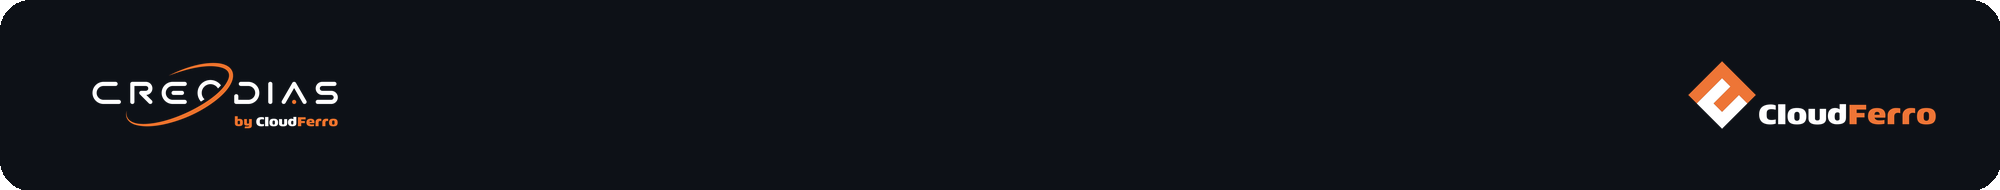

Run on [CREODIAS](https://creodias.eu), an Earth observation platform by [CloudFerro](https://cloudferro.com). The archive is mounted read only at `/eodata` on every CREODIAS virtual machine; this notebook copies the files it needs from there to local disk.
